# 05 — Evaluation on the test sets (internal and external)

**Goal.** Measure the models **once** on patients never used before:
- **A-test** (4 068 patients) — *internal* evaluation, same hospital as the training data;
- **all of hospital B** (20 000 patients) — *external* evaluation, another hospital.

Then quantify the loss between the two (objective **O3** of Deliverable 1) and repeat the whole
experiment in the reverse direction, **B → A**, as Deliverable 1 commits to.

**Rules.** Nothing is fitted on a test set. The alert thresholds are chosen on the calibration
patients. Every number comes with a **95 % confidence interval from a patient-level bootstrap**
(1 000 resamples).

**Inputs.** `features_baseline.pkl`, `patients_splits.csv` (notebook 02), `baseline_logistic.joblib`
(notebook 04) and `sepsis_utils.py`.
**Outputs.** Figures in `report/figures/`, tables in `report/tables/`.

## 0. Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sepsis_utils import (FastMetrics, QuantileClipper, alert_metrics, bootstrap_p_value, holm, logit,
                          patient_bootstrap, percentile_ci, predict_risk, qsofa_score, reliability_table)

SEED = 42
N_BOOT = 1000                 # bootstrap resamples (200 is enough for a quick first run)
ALERT_RATES = [0.05, 0.10]    # share of hours that raise an alert
PROCESSED = Path("../data/processed")
FIG = Path("../report/figures")
TABLES = Path("../report/tables")
FIG.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 40)

features = pd.read_pickle(PROCESSED / "features_baseline.pkl")
patients = pd.read_csv(PROCESSED / "patients_splits.csv")
bundle_A = joblib.load(PROCESSED / "baseline_logistic.joblib")    # trained on A-train, Platt on A-calib (notebook 04)
print(features.shape, "| model of notebook 04, best setting:", bundle_A["best_params"])

(1552210, 80) | model of notebook 04, best setting: {'model__C': 0.001, 'model__class_weight': None}


## 1. Evaluation sets and scores of the four models

For each evaluation set we keep a small table: the patient, the label of each hour and the risk given
by each of the four models. Nothing is fitted here: the logistic regression and its Platt correction
are the ones saved in notebook 04. The majority class predicts the share of positive hours of A-train
for everyone.

In [2]:
split = features["patient_id"].map(patients.set_index("patient_id")["split"])
hospital = features["hospital"]

def rows(h, s=None):
    # rows of hospital h, optionally only the patients of split s (train / calib / test)
    mask = (hospital == h) if s is None else (hospital == h) & (split == s)
    return features[mask]

def score_models(d, bundle, train_prevalence):
    # small table: patient, label and the risk given by each of the four models
    p_raw, p_platt = predict_risk(bundle, d)
    return pd.DataFrame({
        "patient_id": d["patient_id"].to_numpy(),
        "SepsisLabel": d["SepsisLabel"].to_numpy(),
        "majority class": train_prevalence,
        "qSOFA rule": qsofa_score(d).to_numpy(),
        "logistic": p_raw,
        "logistic + Platt": p_platt,
    })

prev_A = rows("A", "train")["SepsisLabel"].mean()     # share of positive hours in A-train
ev = {
    "A-calib": score_models(rows("A", "calib"), bundle_A, prev_A),
    "A-test (internal)": score_models(rows("A", "test"), bundle_A, prev_A),
    "B (external)": score_models(rows("B"), bundle_A, prev_A),     # all 20 000 patients of hospital B
}
pd.DataFrame({name: {"patients": d["patient_id"].nunique(), "hours": len(d),
                     "share of positive hours": d["SepsisLabel"].mean()}
              for name, d in ev.items()}).T

,patients,hours,share of positive hours
A-calib,4067.0,157812.0,0.0217
A-test (internal),4068.0,159397.0,0.0214
B (external),20000.0,761995.0,0.0141


## 2. Alert thresholds, fixed on A-calib

An alert is raised when the predicted risk is above a threshold. A threshold of 0.5 is meaningless
here (almost all risks are below 20 %), so the threshold is set to raise an alert on **5 %** (or
**10 %**) of the hours **of A-calib**. It is then applied unchanged to the test sets: choosing it on a
test set would be leakage. Platt scaling does not change the order of the risks, so it gives the same
alerts; the qSOFA rule keeps its alert at a score of 2.

In [3]:
def alert_thresholds(calib_scores):
    return {f"alert {int(r * 100)} %": float(np.quantile(calib_scores, 1 - r)) for r in ALERT_RATES}

thresholds_A = alert_thresholds(ev["A-calib"]["logistic"])
thresholds_A

{'alert 5 %': 0.06526861849213081, 'alert 10 %': 0.04313039737725476}

## 3. Metrics with 95 % confidence intervals

**Patient-level bootstrap.** Patients are drawn at random with replacement (as many as in the set),
all hours of each drawn patient are kept, and every metric is recomputed; this is repeated 1 000 times.
The 2.5 % and 97.5 % percentiles of the 1 000 values give the 95 % interval. Resampling *hours* would
treat the ~40 correlated hours of a patient as independent and give intervals that are too narrow.

`FastMetrics` (in `sepsis_utils.py`) computes AUPRC, AUROC, Brier and ECE quickly for each resample.
The next cell checks that it gives the same numbers as scikit-learn.

In [4]:
# Check: the fast metrics equal scikit-learn's on A-test (no resampling)
y_check, s_check = ev["A-test (internal)"]["SepsisLabel"], ev["A-test (internal)"]["logistic"]
fast = FastMetrics(y_check, s_check).compute()
print("AUPRC", round(fast["AUPRC"], 6), round(average_precision_score(y_check, s_check), 6))
print("AUROC", round(fast["AUROC"], 6), round(roc_auc_score(y_check, s_check), 6))
print("Brier", round(fast["Brier"], 6), round(brier_score_loss(y_check, s_check), 6))

AUPRC 0.096888 0.096888
AUROC 0.79703 0.79703
Brier 0.020223 0.020223


In [5]:
def evaluate_set(d, thresholds, n_boot=N_BOOT, seed=SEED):
    # Every metric on the small table d, with its 95 % patient-bootstrap interval.
    # Returns the table and the bootstrap replicates (kept to compute differences later).
    y = d["SepsisLabel"].to_numpy()
    fm = {m: FastMetrics(y, d[m], is_probability=(m != "qSOFA rule"))
          for m in ["majority class", "qSOFA rule", "logistic", "logistic + Platt"]}

    def compute(w=None):
        out = {}
        for m in ["majority class", "qSOFA rule", "logistic"]:
            out.update({(m, k): v for k, v in fm[m].compute(w).items()})
        # Platt keeps the order of the risks: only its calibration differs from the raw model
        out.update({("logistic + Platt", k): v for k, v in fm["logistic + Platt"].compute(w, ranking=False).items()})
        for name, t in thresholds.items():
            out.update({(f"logistic, {name}", k): v for k, v in alert_metrics(y, d["logistic"].to_numpy(), t, w).items()})
        out.update({("qSOFA rule, alert at 2", k): v for k, v in alert_metrics(y, d["qSOFA rule"].to_numpy(), 2, w).items()})
        return out

    point = pd.Series(compute())
    replicates = patient_bootstrap(d["patient_id"], compute, n_boot=n_boot, seed=seed)
    low, high = percentile_ci(replicates)
    table = pd.DataFrame({"estimate": point, "ci_low": low, "ci_high": high})
    table.index.names = ["model", "metric"]
    return table, replicates

results, replicates = {}, {}
for name in ["A-test (internal)", "B (external)"]:
    results[name], replicates[name] = evaluate_set(ev[name], thresholds_A)
    print(name, "done")

A-test (internal) done
B (external) done


In [6]:
def show(results, models, metrics):
    # "estimate [ci_low, ci_high]" for the chosen models and metrics, one column per evaluation set
    cols = {}
    for name, t in results.items():
        sub = t[t.index.get_level_values("model").isin(models) & t.index.get_level_values("metric").isin(metrics)]
        cols[name] = sub.apply(lambda r: f"{r['estimate']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1)
    return pd.DataFrame(cols).reindex(pd.MultiIndex.from_product([models, metrics])).dropna(how="all")

# Discrimination and calibration
show(results, ["majority class", "qSOFA rule", "logistic", "logistic + Platt"],
     ["AUPRC", "AUPRC_lift", "AUROC", "Brier", "ECE"])

A-test (internal)          B (external)
majority class   AUPRC       0.021 [0.019, 0.023]  0.014 [0.013, 0.015]
                 AUPRC_lift  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]
                 AUROC       0.500 [0.500, 0.500]  0.500 [0.500, 0.500]
                 Brier       0.021 [0.019, 0.023]  0.014 [0.013, 0.015]
                 ECE         0.000 [0.000, 0.003]  0.008 [0.007, 0.008]
qSOFA rule       AUPRC       0.026 [0.024, 0.030]  0.018 [0.017, 0.020]
                 AUPRC_lift  1.237 [1.158, 1.330]  1.286 [1.231, 1.349]
                 AUROC       0.577 [0.556, 0.597]  0.578 [0.567, 0.590]
logistic         AUPRC       0.097 [0.086, 0.112]  0.059 [0.052, 0.067]
                 AUPRC_lift  4.524 [3.983, 5.265]  4.154 [3.702, 4.723]
                 AUROC       0.797 [0.776, 0.816]  0.733 [0.720, 0.747]
                 Brier       0.020 [0.018, 0.022]  0.014 [0.013, 0.015]
                 ECE         0.003 [0.002, 0.005]  0.002 [0.001, 0.002]
logistic + Platt Brier       0.020 [0.018, 0.022]  0.014 [0.013, 0.015]
                 ECE         0.003 [0.002, 0.005]  0.002 [0.001, 0.002]

In [7]:
# Alerts: what happens at the bedside with each alert rule
show(results, ["logistic, alert 5 %", "logistic, alert 10 %", "qSOFA rule, alert at 2"],
     ["alert_rate", "sensitivity", "PPV", "false_alarms_per_patient_day"])

A-test (internal)  \
logistic, alert 5 %    alert_rate                    0.057 [0.048, 0.067]   
                       sensitivity                   0.302 [0.262, 0.347]   
                       PPV                           0.113 [0.099, 0.129]   
                       false_alarms_per_patient_day  1.214 [1.006, 1.446]   
logistic, alert 10 %   alert_rate                    0.110 [0.098, 0.122]   
                       sensitivity                   0.468 [0.422, 0.513]   
                       PPV                           0.091 [0.081, 0.102]   
                       false_alarms_per_patient_day  2.396 [2.128, 2.677]   
qSOFA rule, alert at 2 alert_rate                    0.043 [0.039, 0.046]   
                       sensitivity                   0.080 [0.062, 0.099]   
                       PPV                           0.040 [0.031, 0.050]   
                       false_alarms_per_patient_day  0.980 [0.905, 1.064]   

                                                             B (external)  
logistic, alert 5 %    alert_rate                    0.024 [0.021, 0.027]  
                       sensitivity                   0.173 [0.153, 0.193]  
                       PPV                           0.103 [0.090, 0.116]  
                       false_alarms_per_patient_day  0.512 [0.440, 0.587]  
logistic, alert 10 %   alert_rate                    0.048 [0.043, 0.052]  
                       sensitivity                   0.281 [0.257, 0.306]  
                       PPV                           0.084 [0.076, 0.092]  
                       false_alarms_per_patient_day  1.046 [0.950, 1.144]  
qSOFA rule, alert at 2 alert_rate                    0.029 [0.027, 0.030]  
                       sensitivity                   0.072 [0.062, 0.082]  
                       PPV                           0.035 [0.030, 0.040]  
                       false_alarms_per_patient_day  0.671 [0.637, 0.706]

**How to read the tables.**
- `AUPRC_lift` = AUPRC divided by the share of positive hours: how many times better than random.
  Needed to compare A and B, because sepsis is rarer in B, which lowers the AUPRC mechanically.
- `sensitivity`: share of septic hours that raise an alert. `PPV`: share of alerts that are septic hours.
  `false_alarms_per_patient_day`: alerts on non-septic hours, per 24 hours of stay.
- The alert rate on the test sets can differ from 5 % / 10 %: the threshold was fixed on A-calib.
- The ECE of a resample is a little higher on average than the ECE of the real set (random noise
  in the groups always adds error), so the ECE estimate can sit near the lower end of its interval.

## 4. The drop between hospitals (objective O3)

Difference internal − external (positive = worse in B for AUROC and AUPRC, negative = worse in B for
Brier and ECE). The two sets contain different patients and are resampled independently, so the
difference of the two bootstrap replicates, resample by resample, gives the interval of the difference.

In [8]:
DROP_METRICS = [("logistic", "AUROC"), ("logistic", "AUPRC"), ("logistic", "AUPRC_lift"),
                ("logistic", "Brier"), ("logistic", "ECE"),
                ("logistic + Platt", "Brier"), ("logistic + Platt", "ECE")]

def drop_table(results, replicates, internal, external):
    out = []
    for model, metric in DROP_METRICS:
        diff = replicates[internal][(model, metric)] - replicates[external][(model, metric)]
        low, high = diff.quantile([0.025, 0.975])
        est_int = results[internal].loc[(model, metric), "estimate"]
        est_ext = results[external].loc[(model, metric), "estimate"]
        out.append({"model": model, "metric": metric, "internal": est_int, "external": est_ext,
                    "internal - external": est_int - est_ext, "ci_low": low, "ci_high": high,
                    "significant (CI excludes 0)": not (low <= 0 <= high)})
    return pd.DataFrame(out)

drop_AB = drop_table(results, replicates, "A-test (internal)", "B (external)")
drop_AB

,model,metric,internal,external,internal - external,ci_low,ci_high,significant (CI excludes 0)
0,logistic,AUROC,0.7970,0.7331,0.0639,0.0381,0.0879,True
1,logistic,AUPRC,0.0969,0.0588,0.0381,0.0248,0.0540,True
2,logistic,AUPRC_lift,4.5236,4.1535,0.3701,-0.4546,1.2258,False
3,logistic,Brier,0.0202,0.0137,0.0065,0.0044,0.0085,True
4,logistic,ECE,0.0029,0.0016,0.0014,0.0004,0.0037,True
5,logistic + Platt,Brier,0.0202,0.0137,0.0065,0.0044,0.0085,True
6,logistic + Platt,ECE,0.0029,0.0016,0.0014,0.0004,0.0037,True


## 5. Calibration in the other hospital

Same reliability diagram as in notebook 04 (10 groups with the same number of hours), now on A-test
and on B. The Platt correction was learned on A-calib: it cannot know that sepsis is rarer in B.

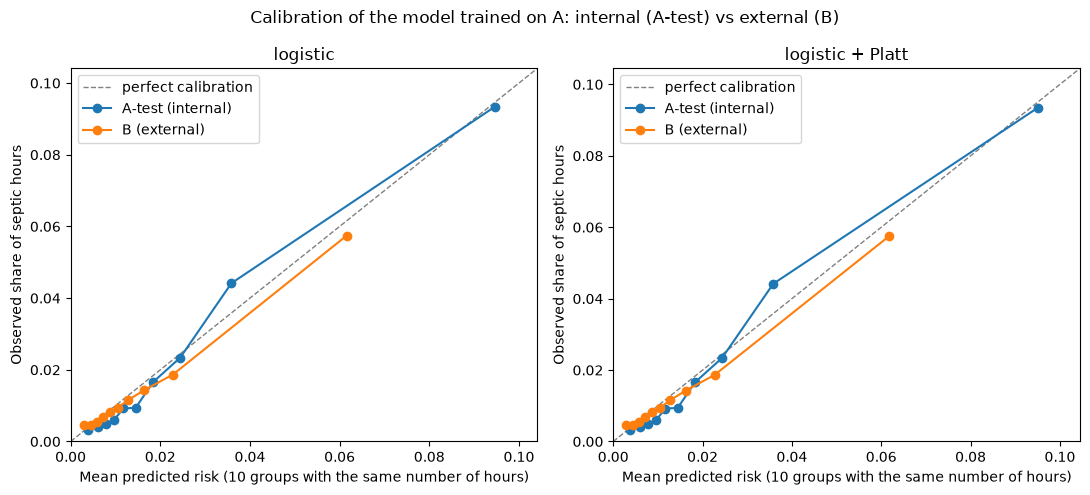

,mean predicted risk (raw),mean predicted risk (Platt),observed share of positive hours
A-test (internal),0.0227,0.0227,0.0214
B (external),0.0153,0.0153,0.0141


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, model in zip(axes, ["logistic", "logistic + Platt"]):
    tables = {name: reliability_table(ev[name]["SepsisLabel"], ev[name][model])
              for name in ["A-test (internal)", "B (external)"]}
    lim = 1.1 * max(max(t["mean_predicted"].max(), t["observed"].max()) for t in tables.values())
    ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=1, label="perfect calibration")
    for name, t in tables.items():
        ax.plot(t["mean_predicted"], t["observed"], marker="o", label=name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("Mean predicted risk (10 groups with the same number of hours)")
    ax.set_ylabel("Observed share of septic hours")
    ax.set_title(model)
    ax.legend()
fig.suptitle("Calibration of the model trained on A: internal (A-test) vs external (B)")
fig.tight_layout()
fig.savefig(FIG / "evaluation_reliability_A_to_B.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({name: {"mean predicted risk (raw)": ev[name]["logistic"].mean(),
                     "mean predicted risk (Platt)": ev[name]["logistic + Platt"].mean(),
                     "observed share of positive hours": ev[name]["SepsisLabel"].mean()}
              for name in ["A-test (internal)", "B (external)"]}).T

## 6. Is the logistic regression better than the qSOFA rule?

**Paired bootstrap.** In each resample, both models are scored on the *same* drawn patients, and their
difference is recorded. The two-sided p-value is the share of resamples where the difference falls on
the other side of 0 (with 1 000 resamples, the smallest possible p-value is about 0.002). Four tests
(AUPRC and AUROC, on A-test and on B) → **Holm correction**.

This replaces the DeLong test planned in Deliverable 1: DeLong assumes independent observations, but the
hours of one patient are not independent, so its p-values would be too small.

In [10]:
def paired_comparison(d, n_boot=N_BOOT, seed=SEED):
    y = d["SepsisLabel"].to_numpy()
    f_log = FastMetrics(y, d["logistic"])
    f_q = FastMetrics(y, d["qSOFA rule"], is_probability=False)

    def difference(w=None):
        a, b = f_log.compute(w, calibration=False), f_q.compute(w, calibration=False)
        return {"AUPRC": a["AUPRC"] - b["AUPRC"], "AUROC": a["AUROC"] - b["AUROC"]}

    point = difference()
    reps = patient_bootstrap(d["patient_id"], difference, n_boot=n_boot, seed=seed)
    return [{"metric": m, "logistic - qSOFA": point[m], "ci_low": reps[m].quantile(0.025),
             "ci_high": reps[m].quantile(0.975), "p_value": bootstrap_p_value(reps[m])} for m in point]

tests = pd.DataFrame([{"set": name, **r} for name in ["A-test (internal)", "B (external)"]
                      for r in paired_comparison(ev[name])])
tests["p_holm"] = holm(tests["p_value"])
tests

,set,metric,logistic - qSOFA,ci_low,ci_high,p_value,p_holm
0,A-test (internal),AUPRC,0.0704,0.0598,0.0841,0.002,0.008
1,A-test (internal),AUROC,0.2197,0.1957,0.2436,0.002,0.008
2,B (external),AUPRC,0.0406,0.0341,0.0484,0.002,0.008
3,B (external),AUROC,0.1546,0.1398,0.1696,0.002,0.008


## 7. Reverse direction: B → A

Same steps as notebook 04, on hospital B: input columns chosen on B-train, same Pipeline, same grid,
5-fold cross-validation grouped by patient, Platt correction on B-calib, alert thresholds on B-calib.
Then evaluation on **B-test** (internal) and **all of hospital A** (external). This takes a few minutes.

In [11]:
B_train = rows("B", "train")

ID_COLS = ["patient_id", "hospital", "SepsisLabel"]
candidates = [c for c in features.columns if c not in ID_COLS + ["Unit2", "Unit2_missing"]]
FEATURES_B = [c for c in candidates if B_train[c].nunique(dropna=True) > 1]
print(len(FEATURES_B), "input columns; removed (single value in B-train):",
      [c for c in candidates if c not in FEATURES_B])

pipeline = Pipeline([
    ("clip", QuantileClipper(lower=0.5, upper=99.5)),
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
grid = {"model__C": [0.001, 0.01, 0.1, 1.0], "model__class_weight": [None, "balanced"]}
search_B = GridSearchCV(pipeline, grid, scoring="average_precision",
                        cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
search_B.fit(B_train[FEATURES_B], B_train["SepsisLabel"].to_numpy(), groups=B_train["patient_id"].to_numpy())

B_calib = rows("B", "calib")
p_calib_B = search_B.best_estimator_.predict_proba(B_calib[FEATURES_B])[:, 1]
platt_B = LogisticRegression(C=np.inf).fit(logit(p_calib_B).reshape(-1, 1), B_calib["SepsisLabel"].to_numpy())
bundle_B = {"pipeline": search_B.best_estimator_, "platt": platt_B, "features": FEATURES_B}
prev_B = B_train["SepsisLabel"].mean()
del B_train, B_calib    # free memory: only the small tables below are needed now
print("best setting on B-train:", search_B.best_params_, "| CV AUPRC:", round(search_B.best_score_, 4))

74 input columns; removed (single value in B-train): ['HospAdmTime_missing']
best setting on B-train: {'model__C': 0.001, 'model__class_weight': None} | CV AUPRC: 0.0783


In [12]:
ev_BA = {"B-calib": score_models(rows("B", "calib"), bundle_B, prev_B),
         "B-test (internal)": score_models(rows("B", "test"), bundle_B, prev_B),
         "A (external)": score_models(rows("A"), bundle_B, prev_B)}      # all 20 336 patients of hospital A
thresholds_B = alert_thresholds(ev_BA["B-calib"]["logistic"])

results_BA, replicates_BA = {}, {}
for name in ["B-test (internal)", "A (external)"]:
    results_BA[name], replicates_BA[name] = evaluate_set(ev_BA[name], thresholds_B)
    print(name, "done")

show(results_BA, ["majority class", "qSOFA rule", "logistic", "logistic + Platt"],
     ["AUPRC", "AUPRC_lift", "AUROC", "Brier", "ECE"])

B-test (internal) done
A (external) done


B-test (internal)          A (external)
majority class   AUPRC       0.014 [0.012, 0.016]  0.022 [0.021, 0.023]
                 AUPRC_lift  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]
                 AUROC       0.500 [0.500, 0.500]  0.500 [0.500, 0.500]
                 Brier       0.014 [0.012, 0.016]  0.021 [0.020, 0.022]
                 ECE         0.000 [0.000, 0.002]  0.008 [0.007, 0.008]
qSOFA rule       AUPRC       0.018 [0.015, 0.021]  0.026 [0.025, 0.027]
                 AUPRC_lift  1.279 [1.161, 1.434]  1.206 [1.175, 1.240]
                 AUROC       0.571 [0.548, 0.594]  0.573 [0.564, 0.581]
logistic         AUPRC       0.089 [0.068, 0.126]  0.057 [0.053, 0.061]
                 AUPRC_lift  6.267 [4.817, 9.162]  2.611 [2.457, 2.799]
                 AUROC       0.784 [0.756, 0.812]  0.700 [0.690, 0.710]
                 Brier       0.013 [0.012, 0.015]  0.021 [0.020, 0.022]
                 ECE         0.002 [0.001, 0.004]  0.006 [0.005, 0.007]
logistic + Platt Brier       0.013 [0.012, 0.015]  0.021 [0.021, 0.022]
                 ECE         0.001 [0.001, 0.003]  0.009 [0.008, 0.010]

In [13]:
show(results_BA, ["logistic, alert 5 %", "logistic, alert 10 %", "qSOFA rule, alert at 2"],
     ["alert_rate", "sensitivity", "PPV", "false_alarms_per_patient_day"])

B-test (internal)  \
logistic, alert 5 %    alert_rate                    0.054 [0.046, 0.062]   
                       sensitivity                   0.340 [0.286, 0.392]   
                       PPV                           0.089 [0.075, 0.106]   
                       false_alarms_per_patient_day  1.172 [0.989, 1.369]   
logistic, alert 10 %   alert_rate                    0.104 [0.093, 0.115]   
                       sensitivity                   0.479 [0.422, 0.533]   
                       PPV                           0.065 [0.056, 0.076]   
                       false_alarms_per_patient_day  2.328 [2.091, 2.585]   
qSOFA rule, alert at 2 alert_rate                    0.027 [0.025, 0.030]   
                       sensitivity                   0.074 [0.052, 0.098]   
                       PPV                           0.038 [0.027, 0.050]   
                       false_alarms_per_patient_day  0.634 [0.574, 0.699]   

                                                             A (external)  
logistic, alert 5 %    alert_rate                    0.134 [0.129, 0.139]  
                       sensitivity                   0.370 [0.351, 0.389]  
                       PPV                           0.060 [0.057, 0.063]  
                       false_alarms_per_patient_day  3.033 [2.919, 3.148]  
logistic, alert 10 %   alert_rate                    0.245 [0.239, 0.251]  
                       sensitivity                   0.527 [0.509, 0.547]  
                       PPV                           0.047 [0.044, 0.049]  
                       false_alarms_per_patient_day  5.596 [5.456, 5.729]  
qSOFA rule, alert at 2 alert_rate                    0.042 [0.040, 0.043]  
                       sensitivity                   0.069 [0.061, 0.076]  
                       PPV                           0.036 [0.031, 0.039]  
                       false_alarms_per_patient_day  0.969 [0.933, 1.003]

In [14]:
drop_BA = drop_table(results_BA, replicates_BA, "B-test (internal)", "A (external)")
drop_BA

,model,metric,internal,external,internal - external,ci_low,ci_high,significant (CI excludes 0)
0,logistic,AUROC,0.7842,0.6996,0.0846,0.0538,0.1138,True
1,logistic,AUPRC,0.0885,0.0566,0.0319,0.0110,0.0696,True
2,logistic,AUPRC_lift,6.2666,2.6106,3.6560,2.2099,6.5528,True
3,logistic,Brier,0.0134,0.0211,-0.0077,-0.0095,-0.0059,True
4,logistic,ECE,0.0017,0.0059,-0.0042,-0.0052,-0.0021,True
5,logistic + Platt,Brier,0.0134,0.0215,-0.0080,-0.0098,-0.0062,True
6,logistic + Platt,ECE,0.0007,0.0089,-0.0082,-0.0086,-0.0058,True


## 8. Figures for the report

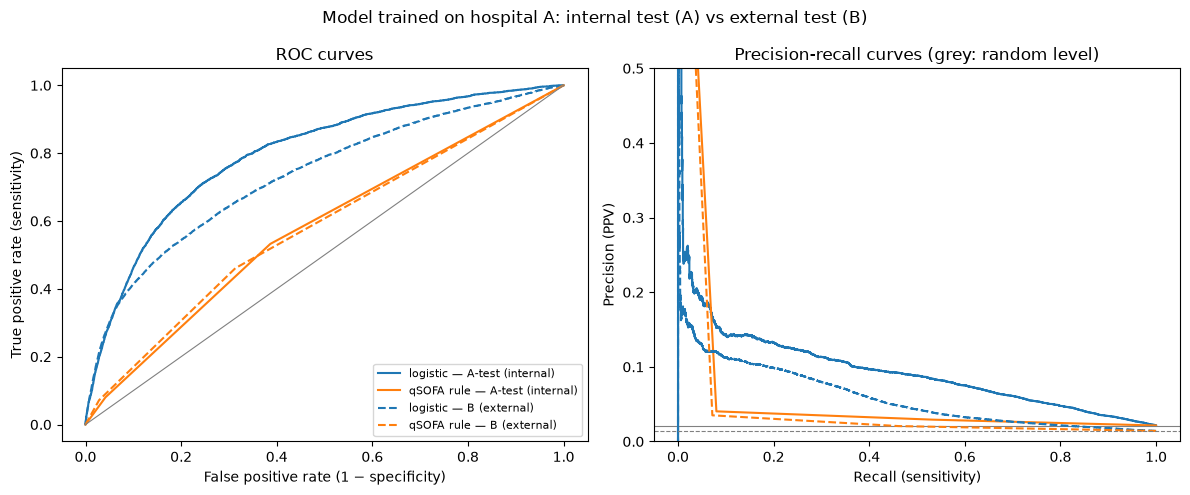

In [15]:
# ROC and precision-recall curves of the model trained on A, internal vs external
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, ls in [("A-test (internal)", "-"), ("B (external)", "--")]:
    y = ev[name]["SepsisLabel"]
    for model, color in [("logistic", "C0"), ("qSOFA rule", "C1")]:
        fpr, tpr, _ = roc_curve(y, ev[name][model])
        prec, rec, _ = precision_recall_curve(y, ev[name][model])
        axes[0].plot(fpr, tpr, ls=ls, color=color, label=f"{model} — {name}")
        axes[1].plot(rec, prec, ls=ls, color=color, label=f"{model} — {name}")
    axes[1].axhline(y.mean(), ls=ls, color="grey", lw=0.8)
axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8)
axes[0].set_xlabel("False positive rate (1 − specificity)")
axes[0].set_ylabel("True positive rate (sensitivity)")
axes[0].set_title("ROC curves")
axes[1].set_xlabel("Recall (sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].set_title("Precision-recall curves (grey: random level)")
axes[1].set_ylim(0, 0.5)
axes[0].legend(fontsize=8)
fig.suptitle("Model trained on hospital A: internal test (A) vs external test (B)")
fig.tight_layout()
fig.savefig(FIG / "evaluation_curves_A_to_B.png", dpi=150, bbox_inches="tight")
plt.show()

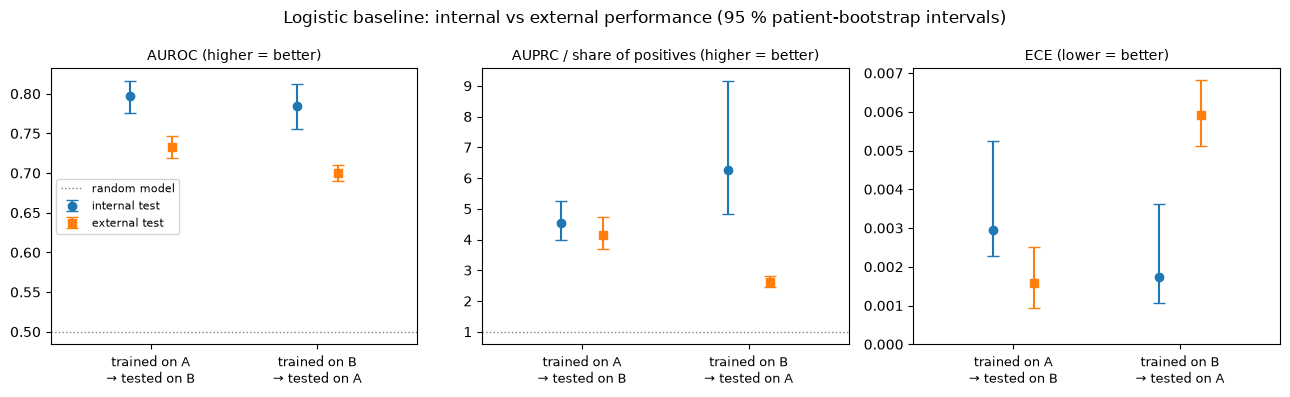

In [16]:
# Internal vs external, both directions, logistic regression, with 95 % intervals
summary = []
for direction, res, internal, external in [("A → B", results, "A-test (internal)", "B (external)"),
                                           ("B → A", results_BA, "B-test (internal)", "A (external)")]:
    for test, name in [("internal", internal), ("external", external)]:
        for metric in ["AUROC", "AUPRC_lift", "ECE"]:
            summary.append({"direction": direction, "test": test, "metric": metric,
                            **res[name].loc[("logistic", metric)].to_dict()})
summary = pd.DataFrame(summary)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
titles = {"AUROC": "AUROC (higher = better)",
          "AUPRC_lift": "AUPRC / share of positives (higher = better)",
          "ECE": "ECE (lower = better)"}
random_level = {"AUROC": 0.5, "AUPRC_lift": 1.0}        # value of a model that predicts at random
for ax, metric in zip(axes, ["AUROC", "AUPRC_lift", "ECE"]):
    for j, (test, marker) in enumerate([("internal", "o"), ("external", "s")]):
        s = summary[(summary["metric"] == metric) & (summary["test"] == test)]
        x = np.arange(2) + (j - 0.5) * 0.25
        ax.errorbar(x, s["estimate"], yerr=[s["estimate"] - s["ci_low"], s["ci_high"] - s["estimate"]],
                    fmt=marker, capsize=4, label=f"{test} test", color=f"C{j}")
    if metric in random_level:
        ax.axhline(random_level[metric], color="grey", ls=":", lw=1, label="random model")
    else:
        ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(2), ["trained on A\n→ tested on B", "trained on B\n→ tested on A"], fontsize=9)
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(titles[metric], fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Logistic baseline: internal vs external performance (95 % patient-bootstrap intervals)")
fig.tight_layout()
fig.savefig(FIG / "evaluation_internal_vs_external.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save the tables for the report

In [17]:
all_results = pd.concat({"A → B": pd.concat(results), "B → A": pd.concat(results_BA)},
                        names=["direction", "evaluation set", "model", "metric"])
all_results.to_csv(TABLES / "evaluation_metrics.csv")
pd.concat([drop_AB.assign(direction="A → B"), drop_BA.assign(direction="B → A")]).to_csv(
    TABLES / "evaluation_drop.csv", index=False)
tests.to_csv(TABLES / "evaluation_logistic_vs_qsofa.csv", index=False)
print("saved in", TABLES)

saved in ..\report\tables


## 10. Observations

- **Internal test (A-test):** The logistic regression is clearly better than the two simple baselines. Its AUROC is 0.797 [0.776, 0.816] and its AUPRC is 0.097 [0.086, 0.112], about 4.5 times the share of positive hours (the level of a random model). The qSOFA rule is only a little better than random (AUROC 0.577, AUPRC lift 1.24). The model is also well calibrated: ECE 0.003, and a mean predicted risk of 2.27 % for 2.14 % of septic hours.
- **External test (B):** The model still works in hospital B, but less well: AUROC 0.733 [0.720, 0.747] and AUPRC 0.059 [0.052, 0.067]. Part of the lower AUPRC only comes from the fact that sepsis is rarer in B (1.41 % of the hours against 2.14 % in A). Compared with the random level, the lift stays close to the one in A (4.15 against 4.52).
- **The drop (O3):** Between A and B the AUROC loses 0.064 [0.038, 0.088] and the AUPRC loses 0.038 [0.025, 0.054], and both drops are significant. But the drop of the AUPRC lift (0.37 [−0.45, 1.23]) is not significant, so most of the AUPRC drop is due to the lower prevalence in B, not to a worse ranking of the patients. Brier and ECE are even a little better in B, but only because the risks and the prevalence are smaller there, so the absolute errors are smaller too. With such a rare outcome the Brier score is almost the same as the one of the majority class, so it does not tell us much.
- **Calibration in B:** We expected a problem, because the Platt correction was learned on A-calib, where sepsis is more frequent. In fact the calibration in B stays good: the mean predicted risk is 1.53 % for 1.41 % of septic hours, and the ECE is 0.002. The raw model already gives lower risks to the patients of B, so it follows the lower prevalence without help. The reliability diagram only shows a small over-estimation of the highest risks in B (about 6.2 % predicted for 5.7 % observed in the last group) and a small under-estimation of the lowest ones. Platt scaling changes nothing here: the raw logistic regression (C = 0.001, no class weights) was already calibrated, so the two diagrams and the Brier and ECE values are the same.
- **Alerts:** The thresholds fixed on A-calib give the expected alert rates in A-test (5.7 % and 11.0 %). The 5 % rule finds 30 % of the septic hours, with a PPV of 11 % and 1.2 false alarms per patient-day. The 10 % rule finds 47 % of them, with 2.4 false alarms per patient-day. In B the same thresholds raise only half as many alerts (2.4 % and 4.8 % of the hours), because the risks are lower there. The PPV stays similar (10 % and 8 %), but the sensitivity falls to 17 % and 28 %. The qSOFA rule at 2 is much weaker at the bedside: it finds only 7 to 8 % of the septic hours, with a PPV of 3.5 to 4 %. It gives almost as many false alarms as the logistic 5 % rule in A (0.98 against 1.21 per patient-day) and even more in B (0.67 against 0.51), while it finds 2 to 4 times fewer septic hours.
- **Logistic vs qSOFA:** The logistic regression is better than qSOFA on both sets and for both metrics: +0.22 AUROC and +0.07 AUPRC on A-test, +0.15 AUROC and +0.04 AUPRC on B. The four p-values are 0.002, the smallest possible value with 1 000 resamples, and they stay significant after the Holm correction (0.008).
- **Reverse direction (B → A):** The model trained on B chooses the same setting (C = 0.001, no class weights) and uses 74 input columns, because `HospAdmTime_missing` has a single value in B-train. Its internal result is close to the model of A (AUROC 0.784 [0.756, 0.812] on B-test), but it transfers worse. In hospital A its AUROC falls to 0.700 [0.690, 0.710], a drop of 0.085 [0.054, 0.114]. Its AUPRC also falls (from 0.089 to 0.057) even though sepsis is more frequent in A, so this time the loss is real and not only an effect of the prevalence: the lift falls from 6.3 to 2.6, and this drop is significant. The calibration gets worse in A (ECE 0.006), and the Platt correction learned on B-calib makes it even worse (0.009): section 11 shows that it over-estimates the risk of the patients of A. The thresholds of B-calib do not transfer either: in A they raise alerts on 13 % and 25 % of the hours instead of 5 % and 10 %, with 3.0 and 5.6 false alarms per patient-day, which would quickly cause alarm fatigue. The interval of the internal lift on B-test is wide ([4.8, 9.2]), so this internal value is not very precise. In both directions, the alert thresholds (and the calibration) should be fixed again on local data before using the model in a new hospital.
- **Changes from Deliverable 1:** The DeLong test was replaced by a paired patient-level bootstrap, because the hours of one patient are not independent and DeLong would give p-values that are too small.

## 11. Adapting the alerts and the calibration to the new hospital

The first results show that each model ranks the patients of the other hospital reasonably well, but the
**alert thresholds** do not transfer (too few alerts in B, far too many in A), and for B → A the
**calibration** does not transfer either. Here each model is kept as it is, and only these two things are
adapted with the **calibration patients of the target hospital**:

- **local thresholds**: the 5 % and 10 % quantiles of the target's own scores. No label is needed, so in
  practice this only needs the scores of the first patients of the new hospital;
- **local intercept**: the risks are shifted on the logit scale so that their mean equals the share of
  positive hours of the target. Only this share is needed, not the label of each hour;
- **local Platt**: the Platt correction is learned again on the labelled calibration patients of the target.

The adapted versions are evaluated on the **test patients of the target only** (B-test for A → B, A-test
for B → A), which were never used. The model without adaptation is evaluated on the same patients, so the
comparison is fair and paired. These numbers are therefore not directly comparable with section 3, which
used all the patients of the external hospital.

In [18]:
from scipy.optimize import brentq
from scipy.special import expit
from sklearn.base import clone

def adapt_to_target(bundle, train_prevalence, target):
    # Scores of the model on the calibration and test patients of the target hospital.
    # The calibration patients are used to adapt, the test patients only to evaluate.
    calib = score_models(rows(target, "calib"), bundle, train_prevalence)
    test = score_models(rows(target, "test"), bundle, train_prevalence)
    y_c = calib["SepsisLabel"].to_numpy()
    z_c = logit(calib["logistic"].to_numpy())
    z_t = logit(test["logistic"].to_numpy())

    # local Platt: the same correction as before, but learned on the target hospital
    platt_local = LogisticRegression(C=np.inf).fit(z_c.reshape(-1, 1), y_c)
    test["logistic + local Platt"] = platt_local.predict_proba(z_t.reshape(-1, 1))[:, 1]

    # local intercept: shift the risks so that their mean equals the local share of positive hours
    shift = brentq(lambda s: expit(z_c + s).mean() - y_c.mean(), -10, 10)
    test["logistic + local intercept"] = expit(z_t + shift)

    # local thresholds: quantiles of the target's own scores (no label needed)
    return test, alert_thresholds(calib["logistic"]), shift

test_AB, local_thresholds_AB, shift_AB = adapt_to_target(bundle_A, prev_A, "B")   # model of A, used in B
test_BA, local_thresholds_BA, shift_BA = adapt_to_target(bundle_B, prev_B, "A")   # model of B, used in A

# thresholds of the source hospital vs local thresholds, and the intercept shift
pd.DataFrame({
    "A → B (model of A)": {**{f"{k}, source threshold": v for k, v in thresholds_A.items()},
                           **{f"{k}, local threshold": v for k, v in local_thresholds_AB.items()},
                           "intercept shift (logit scale)": shift_AB},
    "B → A (model of B)": {**{f"{k}, source threshold": v for k, v in thresholds_B.items()},
                           **{f"{k}, local threshold": v for k, v in local_thresholds_BA.items()},
                           "intercept shift (logit scale)": shift_BA},
})

,A → B (model of A),B → A (model of B)
"alert 5 %, source threshold",0.0653,0.0393
"alert 10 %, source threshold",0.0431,0.0252
"alert 5 %, local threshold",0.0400,0.0690
"alert 10 %, local threshold",0.0275,0.0475
intercept shift (logit scale),-0.0760,0.0357


In [19]:
CAL_MODELS = ["logistic", "logistic + Platt", "logistic + local Platt", "logistic + local intercept"]

def evaluate_adaptation(d, source_thresholds, local_thresholds, n_boot=N_BOOT, seed=SEED):
    # Calibration of the four versions of the risk, and alerts with the source and the local thresholds,
    # all on the same patients and the same resamples (so the differences are paired).
    y = d["SepsisLabel"].to_numpy()
    s = d["logistic"].to_numpy()
    fm = {m: FastMetrics(y, d[m]) for m in CAL_MODELS}
    thresholds = {**{f"{k}, source threshold": v for k, v in source_thresholds.items()},
                  **{f"{k}, local threshold": v for k, v in local_thresholds.items()}}

    def compute(w=None):
        out = {}
        for m in CAL_MODELS:     # the order of the risks is the same: only the calibration changes
            out.update({(m, k): v for k, v in fm[m].compute(w, ranking=False).items()})
        for name, t in thresholds.items():
            out.update({(f"logistic, {name}", k): v for k, v in alert_metrics(y, s, t, w).items()})
        return out

    point = pd.Series(compute())
    reps = patient_bootstrap(d["patient_id"], compute, n_boot=n_boot, seed=seed)
    low, high = percentile_ci(reps)
    table = pd.DataFrame({"estimate": point, "ci_low": low, "ci_high": high})
    table.index.names = ["model", "metric"]
    return table, reps

results_adapt, replicates_adapt = {}, {}
for name, d, source_thr, local_thr in [("A → B (on B-test)", test_AB, thresholds_A, local_thresholds_AB),
                                       ("B → A (on A-test)", test_BA, thresholds_B, local_thresholds_BA)]:
    results_adapt[name], replicates_adapt[name] = evaluate_adaptation(d, source_thr, local_thr)
    print(name, "done")

A → B (on B-test) done
B → A (on A-test) done


In [20]:
# Calibration: Platt learned in the source hospital vs local corrections
show(results_adapt, CAL_MODELS, ["Brier", "ECE"])

A → B (on B-test)     B → A (on A-test)
logistic                   Brier  0.014 [0.012, 0.015]  0.021 [0.019, 0.023]
                           ECE    0.002 [0.001, 0.003]  0.006 [0.004, 0.008]
logistic + Platt           Brier  0.014 [0.012, 0.015]  0.021 [0.019, 0.023]
                           ECE    0.002 [0.001, 0.003]  0.009 [0.007, 0.011]
logistic + local Platt     Brier  0.014 [0.012, 0.015]  0.021 [0.019, 0.023]
                           ECE    0.002 [0.002, 0.004]  0.003 [0.002, 0.005]
logistic + local intercept Brier  0.014 [0.012, 0.015]  0.021 [0.019, 0.023]
                           ECE    0.002 [0.001, 0.003]  0.006 [0.004, 0.008]

In [21]:
# Alerts: thresholds of the source hospital vs local thresholds
ALERT_ROWS = [f"logistic, alert {r} %, {kind} threshold" for r in [5, 10] for kind in ["source", "local"]]
show(results_adapt, ALERT_ROWS, ["alert_rate", "sensitivity", "PPV", "false_alarms_per_patient_day"])

A → B (on B-test)  \
logistic, alert 5 %, source threshold  alert_rate                    0.018 [0.013, 0.023]   
                                       sensitivity                   0.173 [0.127, 0.220]   
                                       PPV                           0.137 [0.110, 0.174]   
                                       false_alarms_per_patient_day  0.368 [0.255, 0.484]   
logistic, alert 5 %, local threshold   alert_rate                    0.045 [0.037, 0.053]   
                                       sensitivity                   0.290 [0.239, 0.341]   
                                       PPV                           0.091 [0.075, 0.108]   
                                       false_alarms_per_patient_day  0.981 [0.808, 1.157]   
logistic, alert 10 %, source threshold alert_rate                    0.039 [0.031, 0.046]   
                                       sensitivity                   0.269 [0.220, 0.320]   
                                       PPV                           0.098 [0.081, 0.117]   
                                       false_alarms_per_patient_day  0.836 [0.667, 1.000]   
logistic, alert 10 %, local threshold  alert_rate                    0.095 [0.084, 0.105]   
                                       sensitivity                   0.394 [0.338, 0.450]   
                                       PPV                           0.059 [0.050, 0.068]   
                                       false_alarms_per_patient_day  2.136 [1.905, 2.366]   

                                                                        B → A (on A-test)  
logistic, alert 5 %, source threshold  alert_rate                    0.142 [0.131, 0.154]  
                                       sensitivity                   0.396 [0.354, 0.442]  
                                       PPV                           0.060 [0.053, 0.067]  
                                       false_alarms_per_patient_day  3.199 [2.935, 3.477]  
logistic, alert 5 %, local threshold   alert_rate                    0.058 [0.050, 0.067]  
                                       sensitivity                   0.238 [0.202, 0.278]  
                                       PPV                           0.088 [0.075, 0.101]  
                                       false_alarms_per_patient_day  1.277 [1.097, 1.477]  
logistic, alert 10 %, source threshold alert_rate                    0.251 [0.238, 0.265]  
                                       sensitivity                   0.552 [0.510, 0.597]  
                                       PPV                           0.047 [0.042, 0.052]  
                                       false_alarms_per_patient_day  5.731 [5.427, 6.060]  
logistic, alert 10 %, local threshold  alert_rate                    0.108 [0.098, 0.119]  
                                       sensitivity                   0.338 [0.296, 0.381]  
                                       PPV                           0.067 [0.059, 0.076]  
                                       false_alarms_per_patient_day  2.411 [2.184, 2.660]

**Is the adaptation significantly better?** Both versions are measured on the same resamples, so for each
resample we can compute *new − old* and take the 2.5 % and 97.5 % percentiles, like in section 4.
For Brier, ECE and false alarms, a negative difference means an improvement.

In [22]:
def adaptation_differences(res, reps):
    pairs = [(new, "logistic + Platt", m) for new in ["logistic + local Platt", "logistic + local intercept"]
             for m in ["Brier", "ECE"]]
    for r in [5, 10]:
        pairs += [(f"logistic, alert {r} %, local threshold", f"logistic, alert {r} %, source threshold", m)
                  for m in ["alert_rate", "sensitivity", "PPV", "false_alarms_per_patient_day"]]
    out = []
    for name in res:
        for new, old, m in pairs:
            diff = reps[name][(new, m)] - reps[name][(old, m)]
            low, high = diff.quantile([0.025, 0.975])
            old_value = res[name].loc[(old, m), "estimate"]
            new_value = res[name].loc[(new, m), "estimate"]
            out.append({"direction": name, "new": new, "old": old, "metric": m,
                        "old value": old_value, "new value": new_value, "new - old": new_value - old_value,
                        "ci_low": low, "ci_high": high, "significant (CI excludes 0)": not (low <= 0 <= high)})
    return pd.DataFrame(out)

adaptation_diff = adaptation_differences(results_adapt, replicates_adapt)
adaptation_diff

,direction,new,old,metric,old value,new value,new - old,ci_low,ci_high,significant (CI excludes 0)
0,A → B (on B-test),logistic + local Platt,logistic + Platt,Brier,0.0135,0.0135,4.6285e-05,-2.0833e-05,9.8918e-05,False
1,A → B (on B-test),logistic + local Platt,logistic + Platt,ECE,0.0017,0.0024,7.4115e-04,8.0924e-07,1.1377e-03,True
2,A → B (on B-test),logistic + local intercept,logistic + Platt,Brier,0.0135,0.0135,8.9970e-06,-7.4213e-06,2.3616e-05,False
3,A → B (on B-test),logistic + local intercept,logistic + Platt,ECE,0.0017,0.0019,1.7206e-04,-5.1703e-04,6.6763e-04,False
4,A → B (on B-test),"logistic, alert 5 %, local threshold","logistic, alert 5 %, source threshold",alert_rate,0.0178,0.0450,2.7218e-02,2.3578e-02,3.0723e-02,True
5,A → B (on B-test),"logistic, alert 5 %, local threshold","logistic, alert 5 %, source threshold",sensitivity,0.1727,0.2897,1.1699e-01,8.7988e-02,1.4554e-01,True
6,A → B (on B-test),"logistic, alert 5 %, local threshold","logistic, alert 5 %, source threshold",PPV,0.1374,0.0910,-4.6420e-02,-7.4288e-02,-2.5932e-02,True
7,A → B (on B-test),"logistic, alert 5 %, local threshold","logistic, alert 5 %, source threshold",false_alarms_per_patient_day,0.3675,0.9811,6.1357e-01,5.2727e-01,6.9623e-01,True
8,A → B (on B-test),"logistic, alert 10 %, local threshold","logistic, alert 10 %, source threshold",alert_rate,0.0386,0.0946,5.5945e-02,5.1390e-02,6.0775e-02,True
9,A → B (on B-test),"logistic, alert 10 %, local threshold","logistic, alert 10 %, source threshold",sensitivity,0.2688,0.3942,1.2535e-01,9.8756e-02,1.5539e-01,True


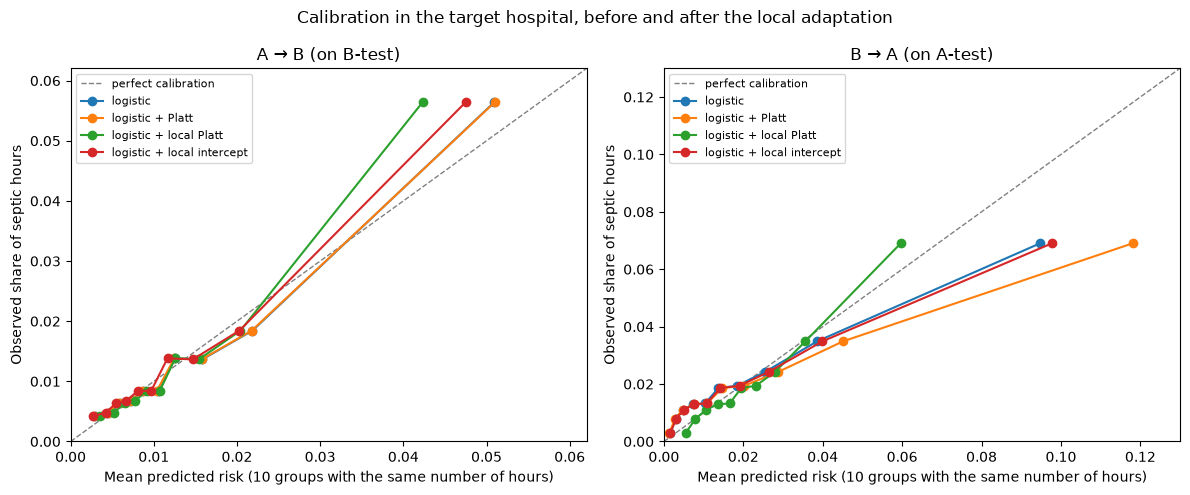

,observed share of positive hours,"mean risk, logistic","mean risk, logistic + Platt","mean risk, logistic + local Platt","mean risk, logistic + local intercept"
A → B (on B-test),0.0141,0.0141,0.0140,0.0134,0.0131
B → A (on A-test),0.0214,0.0218,0.0254,0.0220,0.0225


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, d) in zip(axes, [("A → B (on B-test)", test_AB), ("B → A (on A-test)", test_BA)]):
    tables = {m: reliability_table(d["SepsisLabel"], d[m]) for m in CAL_MODELS}
    lim = 1.1 * max(max(t["mean_predicted"].max(), t["observed"].max()) for t in tables.values())
    ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=1, label="perfect calibration")
    for m, t in tables.items():
        ax.plot(t["mean_predicted"], t["observed"], marker="o", label=m)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("Mean predicted risk (10 groups with the same number of hours)")
    ax.set_ylabel("Observed share of septic hours")
    ax.set_title(name)
    ax.legend(fontsize=8)
fig.suptitle("Calibration in the target hospital, before and after the local adaptation")
fig.tight_layout()
fig.savefig(FIG / "evaluation_local_recalibration.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({name: {"observed share of positive hours": d["SepsisLabel"].mean(),
                     **{f"mean risk, {m}": d[m].mean() for m in CAL_MODELS}}
              for name, d in [("A → B (on B-test)", test_AB), ("B → A (on A-test)", test_BA)]}).T

## 12. What differs between the two hospitals?

To understand why B → A transfers worse than A → B, we compare the input columns of the two hospitals
(this is only descriptive: no label is used and nothing is fitted).

- **Standardized difference** = (mean in A − mean in B) / pooled standard deviation. Above 0.1 in absolute
  value is usually considered a real difference, above 0.5 a large one. For a `_missing` column the mean is
  the share of missing values, so the same measure also compares the missing values. A value of ±inf
  means that the column is constant in each hospital, but with a different value (for example always
  missing in one hospital and never in the other).
- **Coefficients** of the two logistic regressions. The inputs are standardized in the Pipeline, so the
  coefficients can be compared with each other. A column with a large coefficient **and** a large difference
  between the hospitals is a likely reason for the loss. A column used with opposite signs in A and B is
  another warning sign.

In [24]:
shift_rows = {}
for c in candidates:
    x = pd.to_numeric(features[c], errors="coerce").astype(float)
    mean, std = x.groupby(hospital).mean(), x.groupby(hospital).std()
    missing = x.isna().groupby(hospital).mean()
    with np.errstate(divide="ignore", invalid="ignore"):    # inf = constant in each hospital, but with different values
        smd = (mean["A"] - mean["B"]) / np.sqrt((std["A"] ** 2 + std["B"] ** 2) / 2)
    shift_rows[c] = {"mean in A": mean["A"], "mean in B": mean["B"], "standardized difference (A - B)": smd,
                     "missing in A": missing["A"], "missing in B": missing["B"]}
shift_table = pd.DataFrame(shift_rows).T
shift_table["missing difference (A - B)"] = shift_table["missing in A"] - shift_table["missing in B"]

order = shift_table["standardized difference (A - B)"].abs().sort_values(ascending=False).index
print((shift_table["standardized difference (A - B)"].abs() > 0.1).sum(), "columns out of", len(shift_table),
      "with an absolute standardized difference above 0.1")
shift_table.loc[order].head(20)

49 columns out of 75 with an absolute standardized difference above 0.1


,mean in A,mean in B,standardized difference (A - B),missing in A,missing in B,missing difference (A - B)
HCO3_missing,0.1659,0.9794,-2.8891,0.0000,0.0000,0.0000
Chloride_missing,0.1661,0.9190,-2.3077,0.0000,0.0000,0.0000
BaseExcess_missing,0.4008,0.9717,-1.5605,0.0000,0.0000,0.0000
PTT_missing,0.3286,0.7838,-1.0307,0.0000,0.0000,0.0000
DBP_missing,0.3759,0.0309,0.9488,0.0000,0.0000,0.0000
BaseExcess,-0.0169,-3.3154,0.8329,0.4008,0.9717,-0.5709
TroponinI_missing,0.9792,0.7149,0.7896,0.0000,0.0000,0.0000
pH_missing,0.3814,0.7150,-0.7115,0.0000,0.0000,0.0000
PaCO2_missing,0.4068,0.7139,-0.6506,0.0000,0.0000,0.0000
EtCO2_missing,1.0000,0.8286,0.6431,0.0000,0.0000,0.0000


In [25]:
def coefficients(bundle):
    cols = bundle["features"] if "features" in bundle else list(bundle["pipeline"].feature_names_in_)
    return pd.Series(bundle["pipeline"][-1].coef_[0], index=cols)

coefs = pd.DataFrame({"coefficient, model A": coefficients(bundle_A), "coefficient, model B": coefficients(bundle_B)})
coefs["standardized difference (A - B)"] = shift_table["standardized difference (A - B)"]
coefs["opposite signs"] = np.sign(coefs["coefficient, model A"]) * np.sign(coefs["coefficient, model B"]) < 0
coefs["largest |coefficient|"] = coefs[["coefficient, model A", "coefficient, model B"]].abs().max(axis=1)
coefs = coefs.sort_values("largest |coefficient|", ascending=False)
coefs.head(20)

,"coefficient, model A","coefficient, model B",standardized difference (A - B),opposite signs,largest |coefficient|
ICULOS,0.3434,0.2513,0.0143,False,0.3434
Unit1,0.2410,0.1381,0.0369,False,0.2410
Temp,0.2091,0.2260,0.1944,False,0.2260
HR,0.1418,0.2211,0.0609,False,0.2211
Lactate_missing,-0.2025,0.0559,-0.2632,True,0.2025
SBP_missing,0.1993,0.0058,0.0828,False,0.1993
EtCO2_missing,NaN,-0.1939,0.6431,False,0.1939
Unit1_missing,-0.0655,0.1831,0.4018,True,0.1831
Temp_missing,-0.0530,0.1794,-0.0135,True,0.1794
FiO2_missing,-0.1781,-0.0673,-0.6085,False,0.1781


## 13. Model without the hospital-specific columns

The `_missing` columns describe which tests a hospital orders and how often, more than the state of the
patient, and `HospAdmTime` (time between the hospital and the ICU admission) depends on how each hospital
records it. These columns can help inside one hospital but hurt in another one.

We train the same model again **without these columns**, in both directions, with exactly the same steps as
section 7 (Pipeline, grid, 5-fold cross-validation grouped by patient, Platt on the calibration patients,
thresholds on the calibration patients). The list of removed columns is fixed **before** looking at the
results, and the test sets are only used to compare the two versions: nothing is tuned on them.
This takes a few minutes per hospital.

In [26]:
HOSPITAL_SPECIFIC = [c for c in candidates if c.endswith("_missing")] + [c for c in ["HospAdmTime"] if c in candidates]
print(len(HOSPITAL_SPECIFIC), "columns removed:", HOSPITAL_SPECIFIC)

def train_bundle(h, removed):
    # same steps as section 7, on hospital h, without the columns in `removed`
    train = rows(h, "train")
    cols = [c for c in candidates if c not in removed and train[c].nunique(dropna=True) > 1]
    search = GridSearchCV(clone(pipeline), grid, scoring="average_precision",
                          cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
    search.fit(train[cols], train["SepsisLabel"].to_numpy(), groups=train["patient_id"].to_numpy())
    del train
    calib = rows(h, "calib")
    p_calib = search.best_estimator_.predict_proba(calib[cols])[:, 1]
    platt = LogisticRegression(C=np.inf).fit(logit(p_calib).reshape(-1, 1), calib["SepsisLabel"].to_numpy())
    print(f"hospital {h}: {len(cols)} input columns | best setting: {search.best_params_}"
          f" | CV AUPRC: {search.best_score_:.4f}")
    return {"pipeline": search.best_estimator_, "platt": platt, "features": cols}

bundle_A_red = train_bundle("A", HOSPITAL_SPECIFIC)
bundle_B_red = train_bundle("B", HOSPITAL_SPECIFIC)

37 columns removed: ['HR_missing', 'O2Sat_missing', 'Temp_missing', 'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing', 'EtCO2_missing', 'BaseExcess_missing', 'HCO3_missing', 'FiO2_missing', 'pH_missing', 'PaCO2_missing', 'SaO2_missing', 'AST_missing', 'BUN_missing', 'Alkalinephos_missing', 'Calcium_missing', 'Chloride_missing', 'Creatinine_missing', 'Bilirubin_direct_missing', 'Glucose_missing', 'Lactate_missing', 'Magnesium_missing', 'Phosphate_missing', 'Potassium_missing', 'Bilirubin_total_missing', 'TroponinI_missing', 'Hct_missing', 'Hgb_missing', 'PTT_missing', 'WBC_missing', 'Fibrinogen_missing', 'Platelets_missing', 'Unit1_missing', 'HospAdmTime_missing', 'HospAdmTime']
hospital A: 37 input columns | best setting: {'model__C': 0.001, 'model__class_weight': None} | CV AUPRC: 0.0848
hospital B: 38 input columns | best setting: {'model__C': 0.01, 'model__class_weight': None} | CV AUPRC: 0.0690


In [27]:
def evaluate_direction(bundle, train_prevalence, source, target):
    # thresholds on the calibration patients of the source, then internal and external evaluation
    thresholds = alert_thresholds(score_models(rows(source, "calib"), bundle, train_prevalence)["logistic"])
    sets = {f"{source}-test (internal)": score_models(rows(source, "test"), bundle, train_prevalence),
            f"{target} (external)": score_models(rows(target), bundle, train_prevalence)}
    res, reps = {}, {}
    for name, d in sets.items():
        res[name], reps[name] = evaluate_set(d, thresholds)
        print(name, "done")
    return res, reps

results_red, replicates_red = evaluate_direction(bundle_A_red, prev_A, "A", "B")
results_BA_red, replicates_BA_red = evaluate_direction(bundle_B_red, prev_B, "B", "A")

A-test (internal) done
B (external) done
B-test (internal) done
A (external) done


In [28]:
def compare_to_baseline(direction, base_res, base_reps, new_res, new_reps, metrics=("AUROC", "AUPRC_lift", "ECE")):
    out = []
    for name in base_res:
        # same patients and same seed -> same resamples, so the difference is paired.
        # Check: the qSOFA rule does not change between the two runs, so its replicates must be equal.
        paired = np.allclose(base_reps[name][("qSOFA rule", "AUROC")], new_reps[name][("qSOFA rule", "AUROC")])
        for m in metrics:
            diff = new_reps[name][("logistic", m)] - base_reps[name][("logistic", m)]
            low, high = diff.quantile([0.025, 0.975])
            base = base_res[name].loc[("logistic", m), "estimate"]
            new = new_res[name].loc[("logistic", m), "estimate"]
            out.append({"direction": direction, "set": name, "metric": m, "all columns": base,
                        "without hospital-specific columns": new, "difference": new - base,
                        "ci_low": low, "ci_high": high, "significant (CI excludes 0)": not (low <= 0 <= high),
                        "paired resamples": paired})
    return pd.DataFrame(out)

comparison_red = pd.concat([compare_to_baseline("A → B", results, replicates, results_red, replicates_red),
                            compare_to_baseline("B → A", results_BA, replicates_BA, results_BA_red, replicates_BA_red)],
                           ignore_index=True)
comparison_red

,direction,set,metric,all columns,without hospital-specific columns,difference,ci_low,ci_high,significant (CI excludes 0),paired resamples
0,A → B,A-test (internal),AUROC,0.7970,0.7557,-4.1318e-02,-5.6954e-02,-0.0252,True,True
1,A → B,A-test (internal),AUPRC_lift,4.5236,4.1996,-3.2404e-01,-6.6005e-01,0.0484,False,True
2,A → B,A-test (internal),ECE,0.0029,0.0040,1.0247e-03,-1.4791e-03,0.0023,False,True
3,A → B,B (external),AUROC,0.7331,0.7330,-5.6973e-05,-9.3629e-03,0.0103,False,True
4,A → B,B (external),AUPRC_lift,4.1535,4.4985,3.4496e-01,6.4614e-02,0.7577,True,True
5,A → B,B (external),ECE,0.0016,0.0037,2.1267e-03,1.6064e-03,0.0025,True,True
6,B → A,B-test (internal),AUROC,0.7842,0.7382,-4.6020e-02,-6.6058e-02,-0.0267,True,True
7,B → A,B-test (internal),AUPRC_lift,6.2666,6.2116,-5.5004e-02,-9.8281e-01,0.9496,False,True
8,B → A,B-test (internal),ECE,0.0017,0.0019,1.2759e-04,-9.9870e-04,0.0013,False,True
9,B → A,A (external),AUROC,0.6996,0.6999,2.3996e-04,-5.4891e-03,0.0059,False,True


In [29]:
# The drop between hospitals (as in section 4) for the model without hospital-specific columns
drop_red = pd.concat([
    drop_table(results_red, replicates_red, "A-test (internal)", "B (external)").assign(direction="A → B"),
    drop_table(results_BA_red, replicates_BA_red, "B-test (internal)", "A (external)").assign(direction="B → A"),
], ignore_index=True)
drop_red

,model,metric,internal,external,internal - external,ci_low,ci_high,significant (CI excludes 0),direction
0,logistic,AUROC,0.7557,0.7330,0.0227,-0.0074,0.0503,False,A → B
1,logistic,AUPRC,0.0899,0.0636,0.0263,0.0095,0.0453,True,A → B
2,logistic,AUPRC_lift,4.1996,4.4985,-0.2989,-1.3228,0.7029,False,A → B
3,logistic,Brier,0.0203,0.0137,0.0066,0.0045,0.0086,True,A → B
4,logistic,ECE,0.0040,0.0037,0.0003,-0.0015,0.0024,False,A → B
5,logistic + Platt,Brier,0.0203,0.0137,0.0066,0.0045,0.0086,True,A → B
6,logistic + Platt,ECE,0.0034,0.0041,-0.0006,-0.0021,0.0017,False,A → B
7,logistic,AUROC,0.7382,0.6999,0.0383,0.0056,0.0700,True,B → A
8,logistic,AUPRC,0.0878,0.0615,0.0263,0.0047,0.0628,True,B → A
9,logistic,AUPRC_lift,6.2116,2.8337,3.3779,1.8584,6.0390,True,B → A


In [30]:
pd.concat(results_adapt, names=["direction", "model", "metric"]).to_csv(TABLES / "evaluation_local_adaptation_metrics.csv")
adaptation_diff.to_csv(TABLES / "evaluation_local_adaptation_differences.csv", index=False)
shift_table.to_csv(TABLES / "shift_A_vs_B.csv")
coefs.to_csv(TABLES / "coefficients_A_vs_B.csv")
comparison_red.to_csv(TABLES / "evaluation_without_hospital_specific.csv", index=False)
drop_red.to_csv(TABLES / "evaluation_drop_without_hospital_specific.csv", index=False)
print("saved in", TABLES)

saved in ..\report\tables


## 14. Observations on the improvements

- **Local thresholds:** This is the clear gain. Fixed on the calibration patients of the target hospital, the thresholds give the planned alert rate: 4.5 % and 9.5 % of the hours on B-test (instead of 1.8 % and 3.9 % with the thresholds of A), and 5.8 % and 10.8 % on A-test (instead of 14.2 % and 25.1 % with the thresholds of B). In A → B the model now finds more septic hours (29 % instead of 17 % with the 5 % rule), at the price of more false alarms (1.0 instead of 0.4 per patient-day), as expected with a higher alert rate. With these local thresholds the model of A works in B almost as well as in A: with the 5 % rule it finds 29 % of the septic hours on B-test against 30 % on A-test, with 1.0 against 1.2 false alarms per patient-day. In B → A the false alarms fall from 3.2 to 1.3 per patient-day (5 % rule) and from 5.7 to 2.4 (10 % rule), and the PPV goes up. All these differences are significant. Local thresholds only need the scores of the new hospital, not its labels, so they are easy to set in practice.
- **Local calibration (intercept and Platt):** In A → B nothing needs to be corrected: the raw model already predicts 1.41 % on average for 1.41 % of septic hours on B-test, and the local corrections do not help (the local Platt even makes the ECE a little worse, 0.0024 against 0.0017, a very small difference). In B → A the Platt correction learned on B-calib over-estimates the risk in A: 2.54 % predicted for 2.14 % observed on A-test, and about 12 % predicted for 7 % observed in the highest group. The local Platt correction fixes it: the ECE falls from 0.0089 to 0.0025. The local intercept only brings the ECE back to the level of the raw model (0.006), because the average risk of the raw model was already right (2.18 %): the problem is the highest risks, and only a correction of the slope (Platt) can fix it.
- **Differences between the hospitals:** The two hospitals are very different: 49 of the 75 input columns have an absolute standardized difference above 0.1. The largest differences are in the missing values, that is in which tests are ordered: HCO3 and chloride are "never measured so far" in 17 % of the hours in A but in 98 % and 92 % in B; base excess, PTT, pH, PaCO2 and FiO2 are also much more often missing in B, and EtCO2 is never measured in A. Some values also differ (SaO2 91 against 97 %, MAP 79 against 87 mmHg, base excess −0.02 against −3.3). The physiological signals have the same sign and a similar size in the two models (ICULOS, Unit1, temperature, heart rate, FiO2). On the contrary, several `_missing` columns are used in opposite directions: never having had a lactate test lowers the risk in A (−0.20) but raises it a little in B (+0.06), and it is the same for Unit1, temperature, glucose, phosphate and calcium. This supports the idea that the `_missing` columns describe the habits of each hospital more than the patients.
- **Model without hospital-specific columns:** Without the 36 `_missing` columns and `HospAdmTime`, the models keep 37 (A) and 38 (B) input columns. Inside each hospital they lose performance: the AUROC falls from 0.797 to 0.756 on A-test and from 0.784 to 0.738 on B-test (both significant), and the CV AUPRC from 0.093 to 0.085 (A) and from 0.078 to 0.069 (B). So these columns really help inside a hospital. In the other hospital the AUROC does not change at all (0.733 in B and 0.700 in A, as before), and the AUPRC lift even improves a little (4.15 → 4.50 in B, 2.61 → 2.83 in A, both significant). The drop between hospitals becomes smaller (AUROC drop 0.023 instead of 0.064 for A → B, no longer significant, and 0.038 instead of 0.085 for B → A), but mostly because the internal performance falls, not because the external one rises.
- **What to keep for the final model:** (1) The alert thresholds must always be fixed on local data of the hospital where the model is used; this needs no label and is the main fix for the alarm problem. (2) The Platt correction should be learned again locally when labelled patients are available; otherwise the raw model is safer, since in our two directions it was never worse calibrated than the Platt correction of the other hospital. (3) The `_missing` columns help inside a hospital but do not transfer: in the next deliverable both sets of columns will be compared, internal and external, and the choice will depend on the use (one hospital or several). These adaptations do not solve the ranking loss between hospitals (AUROC 0.80 → 0.73 and 0.78 → 0.70): this is the target of the next models (temporal features, non-linear models).